# BIOT 6900 · Module 3 Assignment: Target Triage with Protein Language Models

**Computational Lab 3 · 100 points · due Thursday, October 8 at 6:00 pm**

Apply the Module 3 method to **your own targets from Module 2**, whichever disease you studied. Follow the assignment sheet: each step below matches a numbered step there. Complete every cell marked **TODO**. Helper functions from Part 2 are provided so you can focus on the analysis.

**Before you start:** complete lab Parts 1 and 2; unzip the Module 3 data pack into `data/`; put your Module 2 target file (for example `targets_ad.csv`) next to this notebook.

**Before you submit:** Kernel → Restart & Run All, and check that every cell runs.

In [1]:
# ---------------- YOUR SETTINGS ----------------
TARGETS_FILE = "targets_leukemia.csv"   # Module 2 output: TARGET ALL phase 2, pediatric lymphoid leukemia
DISEASE      = "leukemia"               # output will be targets_leukemia_w3.csv
TOP_N        = 15                       # number of your top targets to carry forward
GENE_COL, SCORE_COL = "gene", "score"   # matches the Module 2 file


In [2]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, GroupKFold, cross_val_predict
from sklearn.metrics import roc_auc_score, average_precision_score

DATA, SEED = Path("Module_3_data"), 6900   # Module 3 data pack folder next to this notebook
for f in ["panel.tsv", "panel_emb_main.npy", "proteome.tsv", "proteome_emb_main.npy", "anchor_variants.tsv"]:
    if not (DATA / f).exists():
        raise FileNotFoundError(f"data/{f} not found. Unzip the Module 3 data pack into data/ next to this notebook.")
if not Path(TARGETS_FILE).exists():
    raise FileNotFoundError(f"{TARGETS_FILE} not found. Copy your Module 2 target file next to this notebook "
                            "and set TARGETS_FILE above.")

panel = pd.read_csv(DATA / "panel.tsv", sep="\t")
X_panel = np.load(DATA / "panel_emb_main.npy").astype("float32")
proteome = pd.read_csv(DATA / "proteome.tsv", sep="\t")
X_prot = np.load(DATA / "proteome_emb_main.npy").astype("float32")
manifest = json.load(open(DATA / "manifest.json"))
assert len(panel) == len(X_panel) and len(proteome) == len(X_prot), "tables and embeddings are misaligned"
if manifest.get("dry_run"):
    print("*** WARNING: DRY RUN data pack (fake data). Numbers are not real biology. ***")
print(f"Panel {X_panel.shape} | proteome {X_prot.shape} | model: {manifest['embedding_models']['main']['model']}")

# ---- Helper functions from Part 2 (provided) ----
def make_model():
    return make_pipeline(StandardScaler(), LogisticRegression(C=0.05, max_iter=5000))

def evaluate(X, y, groups, folds=5):
    # Out-of-fold AUROC and average precision for a random split and a family split.
    y = np.asarray(y).astype(int)
    rand = cross_val_predict(make_model(), X, y, cv=StratifiedKFold(folds, shuffle=True, random_state=SEED),
                             method="predict_proba")[:, 1]
    fam = cross_val_predict(make_model(), X, y, cv=GroupKFold(folds), groups=groups, method="predict_proba")[:, 1]
    return pd.DataFrame({"AUROC": [roc_auc_score(y, rand), roc_auc_score(y, fam)],
                         "Average precision": [average_precision_score(y, rand), average_precision_score(y, fam)]},
                        index=["Random split", "Family split"]).round(3)

def fit_prior(X, y):
    # Fit the tractability prior on all rows given; returns a fitted model with .predict_proba().
    return make_model().fit(X, np.asarray(y).astype(int))

def require(**kw):
    # Stops with a clear message if a TODO is still `...`
    for name, val in kw.items():
        if val is Ellipsis:
            raise NotImplementedError(f"Complete the TODO above: `{name}` is still `...`")

def cosine_matrix(A, B):
    A = A / np.linalg.norm(A, axis=1, keepdims=True)
    B = B / np.linalg.norm(B, axis=1, keepdims=True)
    return A @ B.T

Panel (1201, 960) | proteome (20190, 960) | model: esmc_300m


## Step 1 · Load and map your targets

Keep your top `TOP_N` targets by Module 2 score, then find each gene's row in `proteome.tsv`. **The row number in `proteome.tsv` is the row number in `proteome_emb_main.npy`.** Genes without a reviewed protein (for example non-coding RNAs) will not be found: list them, don't drop them silently.

In [3]:
mine = pd.read_csv(TARGETS_FILE)
mine = mine.rename(columns={GENE_COL: "gene", SCORE_COL: "score"})
mine["gene"] = mine["gene"].astype(str).str.strip().str.upper()
top = mine.sort_values("score", ascending=False).head(TOP_N).reset_index(drop=True)

row_of = {g: i for i, g in enumerate(proteome["gene"])}

# Split the top genes on whether proteome.tsv has a row for them.
# `row` is the position in proteome.tsv, which is also the row in proteome_emb_main.npy.
unmapped = [g for g in top["gene"] if g not in row_of]
targets = top[top["gene"].isin(row_of)].copy()
targets["row"] = targets["gene"].map(row_of)

require(unmapped=unmapped, targets=targets)
targets = targets.reset_index(drop=True)
my_genes = targets["gene"].tolist()
print(f"Top {len(top)} targets: {len(targets)} mapped, {len(unmapped)} unmapped")
print("Unmapped (report these):", unmapped)

# the embeddings are matched by position, so confirm the mapping before relying on it
assert (proteome.loc[targets["row"], "gene"].values == targets["gene"].values).all(), \
    "row lookup is misaligned with proteome.tsv"

targets[["gene", "score", "row"]]


Top 15 targets: 15 mapped, 0 unmapped
Unmapped (report these): []


,gene,score,row
0,HLA-C,0.982481,7234
1,LY86,0.965176,9474
2,APP,0.961909,911
3,EVI2A,0.961445,5278
4,MX2,0.960338,10544
5,NRIP1,0.955192,11315
6,HLA-B,0.953448,7233
7,LRP10,0.947395,9304
8,R3HDM4,0.946285,13878
9,TCL1A,0.945069,17179


## Step 2 · Guard against leakage

Remove **your own targets** from the training panel before fitting anything, so no target is predicted using its own label.

In [4]:
# Leukemia driver genes to hold out alongside the Module 2 targets
FOCUS_GENES = ["TP53", "NOTCH1", "ATM"]
held_out = sorted(set(my_genes) | set(FOCUS_GENES))

# `keep` is True for panel proteins that are NOT among your targets or focus genes.
keep = ~panel["gene"].str.upper().isin(held_out).values

require(keep=keep)
train, X_train = panel[keep].reset_index(drop=True), X_panel[keep]
print(f"Removed {(~keep).sum()} of your targets from the training panel; training on {len(train)} proteins.")
print("Removed from panel:", panel.loc[~keep, "gene"].tolist())
print("Focus genes not in panel (nothing to remove):", [g for g in FOCUS_GENES if g not in set(panel["gene"])])

# no held-out gene may remain in the training set
assert not train["gene"].isin(held_out).any(), "a held-out gene leaked into the training panel"

Removed 2 of your targets from the training panel; training on 1199 proteins.
Removed from panel: ['HLA-C', 'TP53']
Focus genes not in panel (nothing to remove): ['NOTCH1', 'ATM']


## Step 3 · Validate your prior

Report family-split AUROC and average precision on the training panel, exactly as in Part 2. This tells your reader how far to trust the numbers that follow.

In [5]:
# TODO: call evaluate() on the training panel with the any_clinical labels and family groups.
validation = evaluate(X_train, train["any_clinical"], train["family_group"])

require(validation=validation)
print(validation)
print(f"Chance level for average precision = {train['any_clinical'].mean():.3f}")

              AUROC  Average precision
Random split  0.842              0.715
Family split  0.735              0.531
Chance level for average precision = 0.334


## Step 4 · Two priors, by modality

Fit one prior on `sm_clinical` (small molecule) and one on `ab_clinical` (antibody), then predict both for your targets using their rows in `X_prot`.

In [6]:
X_targets = X_prot[targets["row"].values]

# TODO: fit the two priors on the training panel and add columns p_sm and p_ab to `targets`.
#       Hint: fit_prior(X, y).predict_proba(X_new)[:, 1]
targets["p_sm"] = fit_prior(X_train, train["sm_clinical"]).predict_proba(X_targets)[:, 1]
targets["p_ab"] = fit_prior(X_train, train["ab_clinical"]).predict_proba(X_targets)[:, 1]

require(p_sm=targets["p_sm"].iloc[0], p_ab=targets["p_ab"].iloc[0])
targets[["gene", "score", "p_sm", "p_ab"]].round(3)

,gene,score,p_sm,p_ab
0,HLA-C,0.982,0.109,0.105
1,LY86,0.965,0.132,0.198
2,APP,0.962,0.045,0.022
3,EVI2A,0.961,0.003,0.613
4,MX2,0.960,0.250,0.007
5,NRIP1,0.955,0.004,0.000
6,HLA-B,0.953,0.217,0.101
7,LRP10,0.947,0.091,0.028
8,R3HDM4,0.946,0.002,0.000
9,TCL1A,0.945,0.003,0.000


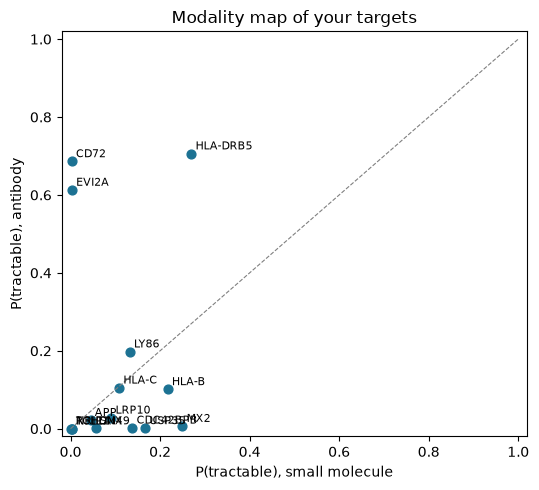

In [7]:
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.scatter(targets.p_sm, targets.p_ab, s=40, c="#1C7293")
for _, r in targets.iterrows():
    ax.annotate(r.gene, (r.p_sm, r.p_ab), fontsize=8, xytext=(3, 3), textcoords="offset points")
ax.plot([0, 1], [0, 1], ls="--", c="grey", lw=0.8)
ax.set_xlabel("P(tractable), small molecule"); ax.set_ylabel("P(tractable), antibody")
ax.set_xlim(-0.02, 1.02); ax.set_ylim(-0.02, 1.02); ax.set_title("Modality map of your targets")
plt.tight_layout(); plt.show()

## Step 5 · Nearest known drug targets

For each target, the three most similar training-panel proteins **with clinical precedence**, with cosine similarity. This is the evidence behind each prior.

In [8]:
drugged = train[train["any_clinical"]].reset_index(drop=True)
X_drugged = X_train[train["any_clinical"].values]
S = cosine_matrix(X_targets, X_drugged)          # rows = your targets, columns = drugged proteins

# TODO: for each target, find the 3 most similar drugged proteins and store them as text
#       like "EGFR (0.81); ERBB2 (0.79); KIT (0.77)" in a new column `nearest_drug_targets`.
#       Hint: np.argsort(-S[i])[:3] gives the column indices of the 3 largest similarities in row i.
targets["nearest_drug_targets"] = [
    "; ".join(f"{drugged.loc[j, 'gene']} ({S[i, j]:.2f})" for j in np.argsort(-S[i])[:3])
    for i in range(len(targets))
]

require(nearest_drug_targets=targets["nearest_drug_targets"].iloc[0])
targets[["gene", "p_sm", "p_ab", "nearest_drug_targets"]].round(2)

,gene,p_sm,p_ab,nearest_drug_targets
0,HLA-C,0.11,0.11,HLA-DRB1 (0.90); CALCB (0.81); RPL7A (0.79)
1,LY86,0.13,0.20,SCNN1G (0.96); NRP1 (0.96); LAMA4 (0.95)
2,APP,0.04,0.02,KCNQ3 (0.94); SEMA4D (0.94); CD74 (0.94)
3,EVI2A,0.00,0.61,MAP3K13 (0.94); CD2 (0.93); E2F7 (0.93)
4,MX2,0.25,0.01,PDE5A (0.96); FRK (0.95); CASP1 (0.95)
5,NRIP1,0.00,0.00,MAP3K1 (0.94); PTHLH (0.94); PLK4 (0.93)
6,HLA-B,0.22,0.10,HLA-DRB1 (0.86); RPL23A (0.83); RPL7A (0.82)
7,LRP10,0.09,0.03,EPOR (0.96); CD248 (0.96); PDCD1 (0.95)
8,R3HDM4,0.00,0.00,PIK3R2 (0.94); E2F1 (0.92); KCNH4 (0.91)
9,TCL1A,0.00,0.00,NDUFA7 (0.95); PDE6G (0.94); PTHLH (0.89)


## Step 6 · Anchor variants (required for everyone)

Report score and within-protein percentile for **APOE R176C (rs7412, ε2)**, **APOE C130R (rs429358, ε4)**, **TREM2 R47H**, and **one p53 hotspot** of your choice. UniProt numbering includes APOE's 18-residue signal peptide (mature names: R158C and C112R).

In [10]:
anchors = pd.read_csv(DATA / "anchor_variants.tsv", sep="\t")
print("Available anchor variants:")
print(anchors[["gene", "variant", "note"]].to_string(index=False))

P53_CHOICE = "R175H"    # TODO: pick one p53 hotspot from the table above

# TODO: build `my_anchors`, the four rows for APOE R176C, APOE C130R, TREM2 R47H, and your p53 choice.
wanted = [("APOE", "R176C"), ("APOE", "C130R"), ("TREM2", "R47H"), ("TP53", P53_CHOICE)]
my_anchors = pd.concat([anchors[(anchors["gene"] == g) & (anchors["variant"] == v)] for g, v in wanted],
                       ignore_index=True)
assert len(my_anchors) == 4, "an anchor variant is missing from anchor_variants.tsv"


require(my_anchors=my_anchors)
print(f"{len(my_anchors)} anchor variants selected")
my_anchors[["gene", "variant", "note", "score", "percentile_in_protein"]].round(2)

Available anchor variants:
 gene variant                                note
 TP53   R175H                             hotspot
 TP53   Y220C          hotspot, druggable crevice
 TP53   G245S                             hotspot
 TP53   R248Q                             hotspot
 TP53   R249S                             hotspot
 TP53   R273H                             hotspot
 TP53   R282W                             hotspot
 APOE   C130R rs429358, defines e4 (C112R mature)
 APOE   R176C   rs7412, defines e2 (R158C mature)
TREM2    R47H         rs75932628, AD risk variant
4 anchor variants selected


,gene,variant,note,score,percentile_in_protein
0,APOE,R176C,"rs7412, defines e2 (R158C mature)",-8.56,11.8
1,APOE,C130R,"rs429358, defines e4 (C112R mature)",7.21,100.0
2,TREM2,R47H,"rs75932628, AD risk variant",-5.16,47.7
3,TP53,R175H,hotspot,-5.97,19.3


## Step 7 · Re-rank and export

Combine your Module 2 evidence with the best-modality tractability prior. Choose the weight `w` (0 = tractability only, 1 = Module 2 only) and **justify it in your report**.

In [11]:
w = 0.6    # TODO: choose your weight and justify it in the report

targets["week2_pct"] = targets["score"].rank(pct=True)
targets["tract"] = targets[["p_sm", "p_ab"]].max(axis=1)

# TODO: compute `final` = w * week2_pct + (1 - w) * (percentile rank of tract), then `rank` (1 = best).
targets["final"] = w * targets["week2_pct"] + (1 - w) * targets["tract"].rank(pct=True)
targets["rank"] = targets["final"].rank(ascending=False, method="first").astype(int)


require(final=targets["final"].iloc[0], rank=targets["rank"].iloc[0])
out = (targets.rename(columns={"score": "week2_score"})
       [["rank", "gene", "week2_score", "p_sm", "p_ab", "nearest_drug_targets", "final"]]
       .sort_values("rank"))
out_file = f"targets_{DISEASE}_w3.csv"
out.to_csv(out_file, index=False)
print(f"Wrote {out_file} ({len(out)} targets). This is your hand-off to Week 4.")
out.round(3)

Wrote targets_leukemia_w3.csv (15 targets). This is your hand-off to Week 4.


,rank,gene,week2_score,p_sm,p_ab,nearest_drug_targets,final
1,1,LY86,0.965,0.132,0.198,SCNN1G (0.96); NRP1 (0.96); LAMA4 (0.95),0.827
3,2,EVI2A,0.961,0.003,0.613,MAP3K13 (0.94); CD2 (0.93); E2F7 (0.93),0.827
0,3,HLA-C,0.982,0.109,0.105,HLA-DRB1 (0.90); CALCB (0.81); RPL7A (0.79),0.787
4,4,MX2,0.960,0.250,0.007,PDE5A (0.96); FRK (0.95); CASP1 (0.95),0.760
6,5,HLA-B,0.953,0.217,0.101,HLA-DRB1 (0.86); RPL23A (0.83); RPL7A (0.82),0.653
2,6,APP,0.962,0.045,0.022,KCNQ3 (0.94); SEMA4D (0.94); CD74 (0.94),0.627
11,7,HLA-DRB5,0.943,0.270,0.706,HLA-DRB1 (0.99); SIGLEC8 (0.88); IFNA10 (0.86),0.560
12,8,CD72,0.943,0.003,0.686,TIGIT (0.92); CD40 (0.91); SIGLEC8 (0.91),0.493
7,9,LRP10,0.947,0.091,0.028,EPOR (0.96); CD248 (0.96); PDCD1 (0.95),0.480
5,10,NRIP1,0.955,0.004,0.000,MAP3K1 (0.94); PTHLH (0.94); PLK4 (0.93),0.480


In [12]:
# Check: how did the ranking move? (useful for report question 1)
moved = targets.assign(week2_rank=targets["score"].rank(ascending=False, method="first").astype(int))
moved["change"] = moved["week2_rank"] - moved["rank"]
moved.sort_values("change")[["gene", "week2_rank", "rank", "change", "p_sm", "p_ab"]].round(2)

,gene,week2_rank,rank,change,p_sm,p_ab
5,NRIP1,6,10,-4,0.00,0.00
8,R3HDM4,9,13,-4,0.00,0.00
9,TCL1A,10,14,-4,0.00,0.00
2,APP,3,6,-3,0.04,0.02
0,HLA-C,1,3,-2,0.11,0.11
7,LRP10,8,9,-1,0.09,0.03
10,SNX9,11,11,0,0.06,0.00
14,CDC42BPB,15,15,0,0.14,0.00
1,LY86,2,1,1,0.13,0.20
4,MX2,5,4,1,0.25,0.01


## Step 8 · Report (3–4 pages, the 40%)

Answer the five questions from the assignment sheet in your report (PDF), using the tables and plots above:

1. **Re-ranking.** Did the prior agree with your Module 2 ranking? Which target moved most, and why? Justify `w`.
2. **Modality.** Pick a target where `p_ab` and `p_sm` differ sharply and explain the biology.
3. **Validation.** Report your family-split metrics (Step 3). Why is this the honest number?
4. **Variants.** Interpret the anchor variant scores (Step 6). Why is a strongly negative score not the same as pathogenic, and what can these models not see?
5. **Limitations and next step.** What can sequence alone not tell you? Which two targets go to Week 4 for structure-based pocket assessment, and why?

Also list any **unmapped** genes from Step 1 and what kind of evidence they would need instead.

## Step 8 · Answers

**1. Re-ranking.** The prior largely did not agree with the Module 2 ranking: across the 15 targets, Spearman ρ between Module 2 score and best-modality tractability is −0.09 (p = 0.74), so the two sources carry essentially independent information. The largest movers were **HLA-DRB5 (12 → 7)** and **CD72 (13 → 8)**, both up five places on high antibody priors (p_ab 0.71 and 0.69), while **NRIP1 (6 → 10), R3HDM4 (9 → 13) and TCL1A (10 → 14)** each fell four places because both priors are near zero for these intracellular regulators. LY86 and EVI2A tied for first (final = 0.827); the tie is broken by table order. I chose **w = 0.6** for three reasons. (a) Module 2 is direct, multi-omic evidence from pediatric ALL patients, whereas the prior is a general, disease-agnostic estimate with only moderate held-out accuracy (family-split AUROC 0.735), so disease evidence should count for more. (b) Module 2 scores in the top 15 are compressed (0.941–0.982), so after percentile ranking even a 0.4 tractability weight is enough to separate near-ties without overriding the disease signal. (c) The result is stable: the same four genes (LY86, EVI2A, HLA-C, MX2) make the top four at every w from 0.5 to 0.7, so the conclusions do not hinge on the exact choice.

**2. Modality.** **CD72** shows the sharpest split (p_sm 0.003 vs p_ab 0.686). CD72 is a type II transmembrane C-type lectin on B-lineage cells that acts as an inhibitory co-receptor of the B-cell receptor. Its accessible extracellular domain and lineage-restricted surface expression are exactly what antibodies, ADCs or CAR-T cells need, while it has no enzymatic active site for a small molecule to occupy. Its nearest drugged neighbours, TIGIT, CD40 and SIGLEC8, are all antibody-targeted immune receptors, which is the evidence behind the prior. **MX2** is the reverse (p_sm 0.250 vs p_ab 0.007): it is an intracellular, interferon-induced dynamin-like GTPase, so it is out of reach of antibodies but has a nucleotide-binding pocket of the kind small molecules exploit; its neighbours (PDE5A, FRK, CASP1) are small-molecule-drugged enzymes.

**3. Validation.** On the leakage-free training panel (1,199 proteins, 400 positives, 820 family groups), the family split gives **AUROC 0.735 and average precision 0.531** (chance AP = 0.334), versus 0.842 / 0.715 for a random split. The family split is the honest number because a random split puts close homologs on both sides of the train/test boundary, so the model gets credit for recognising a paralog whose label it has effectively already seen. My targets are mostly not in the panel and many have no drugged relatives, which is the family-split situation, not the random-split one. The gap between the two splits shows how much of the apparent performance is homology memorisation; HLA-DRB5, whose nearest drugged protein is its paralog HLA-DRB1 at cosine 0.99, is exactly the kind of case where the prior is borrowing a relative's label rather than learning general tractability.

**4. Variants.** APOE R176C (ε2) scores −8.56 (11.8th percentile within APOE), APOE C130R (ε4) +7.21 (100th percentile), TREM2 R47H −5.16 (47.7th) and TP53 R175H −5.97 (19.3rd). These scores are the model's log-likelihood of the mutant residue relative to the wild-type given the sequence context: they measure how evolutionarily unusual a substitution is, not whether it causes disease. ε4 is the clearest example. Arginine at this position is the ancestral residue in other mammals, so the model sees C130R as a return to consensus and scores it as the most favourable change in the protein, even though ε4 is the strongest common genetic risk factor for Alzheimer's disease. Conversely, ε2 scores strongly negative but is protective for Alzheimer's. TREM2 R47H, a validated risk variant, sits at an unremarkable mid-protein percentile, and R175H, a dominant-negative/gain-of-function p53 hotspot, is only at the 19th percentile. So a strongly negative score means "unusual in evolution", which can be neutral, protective or harmful. These models cannot see gain-of-function or dominant-negative effects, dosage and expression context, tissue or cell type, binding partners and complexes, the effect of other variants on the same haplotype, environment, or penetrance in human populations.

**5. Limitations and next step.** From sequence alone we cannot tell whether a protein is expressed on leukemic cells but spared on normal tissue (critical for CD72 and the HLA genes, which are also on healthy B cells and most nucleated cells), whether a druggable pocket actually exists in the folded and possibly complexed protein (LY86 works with CD180), how post-translational modifications, isoforms or disorder affect it, or whether modulating it would kill leukemic cells. The labels themselves reflect drug-development history rather than true tractability, and the family-split AP of 0.53 means many individual predictions will be wrong. I also excluded TP53, NOTCH1 and ATM from training to avoid leakage; only TP53 was in the panel.

For Week 4 structure-based pocket assessment I would carry forward **LY86** and **MX2**. LY86 is ranked first overall, is B-cell-associated, and as MD-1 has a hydrophobic lipid-binding cavity that is a natural candidate pocket. MX2 is fourth overall with the highest small-molecule prior among the top four, and its GTPase domain provides a defined nucleotide pocket to test. The antibody-favoured targets (EVI2A, CD72, HLA-DRB5) would be better assessed by surface expression and epitope analysis than by pocket detection.

**Unmapped genes.** None: all 15 top targets mapped to `proteome.tsv`. Had any been non-coding RNAs or lacked a reviewed protein, they would need non-protein evidence instead, such as expression and knockdown/CRISPR dependency data, and antisense-oligonucleotide or siRNA tractability rather than protein-based priors.